# Feature analysis

Which of the features that go into the rent models carry signal, and which of them say the same thing? The analysis is split by feature type, and uses **only the train rows / train months** (2021-01..2024-03, `sample_type == 'train'`): the validation and test periods are never looked at, so nothing here leaks into model selection.

| | Temporal features | Static features |
|---|---|---|
| what they are | 177 stock, COE and macro series, one value per month | 152 flat, location, MRT, mall, school and demographic features, one value per rental (150 vary on the train rows) |
| rows in the train set | 39 months | 114,841 rentals |
| target | the **monthly mean rent** of the 39 months | the rent **relative to the mean rent of its month** (`rent / month mean`): the flat's premium, with the market trend taken out |

Why two targets: a temporal feature cannot tell two flats of the same month apart, and a static feature does not change over time, so each is judged on the part of the rent it can explain. The relative rent is the same quantity the second stage of the two-stage models predicts.

1. **Temporal features**: usefulness for the monthly rent (correlation of levels and of changes, out-of-sample forecast skill, Lasso selection).
2. **Static features**: usefulness for the relative rent (rank correlation, mutual information, permutation importance, group-level ablation, variance explained by each categorical factor).
3. **DBSCAN location clusters** and the rent: where the clusters are, what rent they carry, and whether they add anything over planning areas and towns.
4. **Correlation and similarity**: heatmaps, families of near-duplicate features, the most correlated pairs, effective dimensionality, and a lookup of the features most similar to a given one.

The tables carry the numbers; the charts only show the head of each ranking.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial import ConvexHull
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Lasso, LassoCV, Ridge
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 70)


def find_root(start):
    """final_report: the folder that holds data/feature_config_static.py (the notebook runs from anywhere inside the repo)."""
    for folder in (start, *start.parents):
        if (folder / 'data' / 'feature_config_static.py').exists():
            return folder
    raise FileNotFoundError('final_report/data/feature_config_static.py not found above ' + str(start))


ROOT = find_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))
from data.feature_config_static import CATEGORICAL_COL, HOT_COL, LABEL, NUMERICAL_COL      # noqa: E402
from data.feature_config_temporal import COE_FEATURE, MACRO_FEATURE, STOCK_FEATURE         # noqa: E402

FINAL = ROOT / 'data' / 'features' / 'final'
GEOJSON = ROOT / 'data' / 'original_dataset' / 'auxiliary' / 'MasterPlan2019PlanningAreaBoundaryNoSea.geojson'
CLUSTER_FILE = ROOT / 'data' / 'features' / 'cleaned' / 'static_features' / 'location_cluster' / 'train_dbscan_cluster.csv'
OUT_DIR = None                       # set a folder to also save the ranking tables as csv

# chart style: the design-system palette (categorical slots 1..5, one-hue sequential blue, blue <-> red diverging around a gray midpoint)
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
CATEGORICAL = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div_blue_red', ['#256abf', '#f0efec', '#e34948'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 100,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'font.size': 9, 'legend.frameon': False, 'lines.linewidth': 2,
})


def month_index(year, month):
    return (np.asarray(year) - 2021) * 12 + np.asarray(month) - 1


def month_date(m):
    """First day of month index m (2021-01 = 0) as a DatetimeIndex."""
    return pd.to_datetime([f'{2021 + k // 12}-{k % 12 + 1:02d}-01' for k in np.atleast_1d(m)])


def year_axis(ax, fmt='%Y'):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a, dtype=np.float64) - np.asarray(b, dtype=np.float64)) ** 2)))


def bh_fdr(p):
    """Benjamini-Hochberg q-values of a Series of p-values."""
    p = p.fillna(1.0)
    order = p.sort_values().index
    ranked = p.loc[order].to_numpy() * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1].clip(max=1.0)
    return pd.Series(q, index=order).reindex(p.index)


def corr_p(r, n):
    """Two-sided p-value of a correlation r over n pairs (t test: it assumes independent months, which trending series are not: read it as a ranking aid)."""
    r = np.clip(r, -0.999999, 0.999999)
    return pd.Series(2 * stats.t.sf(np.abs(r * np.sqrt((n - 2) / (1 - r ** 2))), n - 2), index=r.index)


def save_table(table, name):
    if OUT_DIR is not None:
        Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
        table.to_csv(Path(OUT_DIR) / f'{name}.csv')

## 0. Data

The final feature tables written by `all_features.ipynb` (`data/features/final`), restricted to the train split.

In [2]:
static_all = pd.read_csv(FINAL / 'static_train_scaled.csv')
static_all['month'] = month_index(static_all['RENT_APPROVAL_YEAR'], static_all['RENT_APPROVAL_MONTH'])
train = static_all[static_all['sample_type'] == 'train'].reset_index(drop=True)

TEMPORAL = STOCK_FEATURE + COE_FEATURE + MACRO_FEATURE
temporal_all = pd.read_csv(FINAL / 'temporal_scaled.csv')
temporal_all['month'] = month_index(temporal_all['RENT_APPROVAL_YEAR'], temporal_all['RENT_APPROVAL_MONTH'])
Z = temporal_all[temporal_all['sample_type'] == 'train'].set_index('month')[TEMPORAL]          # 39 months x 177 features (scaled on these months)

rent_month = train.groupby('month')[LABEL].mean()                                               # the temporal target
assert list(rent_month.index) == list(Z.index)
train['rel_rent'] = train[LABEL] / train['month'].map(rent_month)                               # the static target

STATIC_ALL = NUMERICAL_COL + CATEGORICAL_COL + HOT_COL
CONSTANT = [c for c in STATIC_ALL if train[c].nunique() <= 1]
STATIC = [c for c in STATIC_ALL if c not in CONSTANT]
KIND = {**{c: 'numeric' for c in NUMERICAL_COL}, **{c: 'ordinal' for c in CATEGORICAL_COL}, **{c: 'binary' for c in HOT_COL}}

print(f'temporal: {Z.shape[1]} features x {Z.shape[0]} train months ({month_date(Z.index[0])[0]:%Y-%m}..{month_date(Z.index[-1])[0]:%Y-%m}); the {int(Z.isna().sum().sum())} missing values are the month-over-month returns of 2021-01')
print(f'static:   {len(STATIC)} features x {len(train):,} train rentals; left out as constant on the train rows: {CONSTANT}')
print(f'rent: mean ${train[LABEL].mean():,.0f}, std ${train[LABEL].std():,.0f}; relative rent: mean {train["rel_rent"].mean():.3f}, std {train["rel_rent"].std():.3f}')

temporal: 177 features x 39 train months (2021-01..2024-03); the 53 missing values are the month-over-month returns of 2021-01
static:   150 features x 114,841 train rentals; left out as constant on the train rows: ['station_is_open', 'FLAT_MODEL_improved maisonette']
rent: mean $2,594, std $731; relative rent: mean 1.000, std 0.223


# 1. Temporal features

177 features: for each of 53 stocks the monthly mean of the log price, the month-over-month return and the return volatility, plus 12 COE auction features and 6 macroeconomic indicators. They are scaled on the 39 train months, and there are only **39 observations** for 177 candidate predictors, so the usual cautions apply: any trending series correlates with the trending rent (a spurious correlation), and with this many features some will look good by chance.
The analysis therefore asks four different questions, and a feature is trusted when it does well on several:

1. **Levels**: does the feature move with the rent level? (rank correlation; inflated by shared trends)
2. **Changes**: does a month-to-month change of the feature go with the month-to-month change of the rent? (rank correlation of first differences; removes the shared trend; Benjamini-Hochberg q-value over the 177 tests)
3. **Forecast skill**: does a one-feature linear model, fitted on the earlier months, forecast later months better than the rent's own time trend? (rolling origin, three folds of six months)
4. **Multivariate selection**: does a Lasso, tuned by time-series cross-validation, keep the feature?

correlation of the monthly mean rent with the mix-adjusted level: 0.999 (levels), 0.915 (monthly changes)


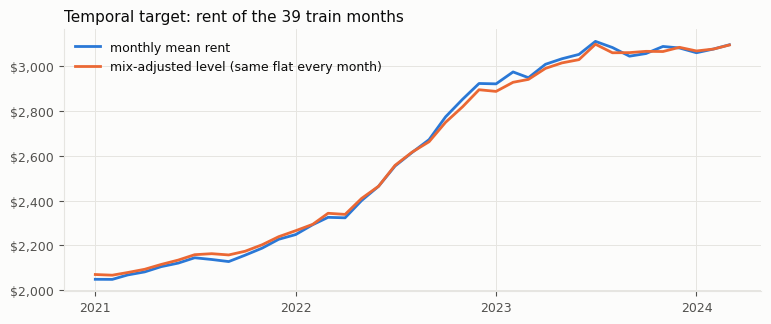

In [3]:
def temporal_type(c):
    if c.startswith('stk_'):
        return 'stock: log price' if c.endswith('_log_price_mean') else 'stock: monthly return' if c.endswith('_mom_return') else 'stock: volatility'
    return 'COE' if c.startswith('coe_') else 'macro'


T_TYPES = ['stock: log price', 'stock: monthly return', 'stock: volatility', 'COE', 'macro']
T_COLOUR = dict(zip(T_TYPES, CATEGORICAL))
y = rent_month

# a second, mix-adjusted target: the level of the same average flat in every month (log rent on the static features and one dummy per month)
S_ADJ = [c for c in STATIC]
X_adj = train[S_ADJ].astype(np.float32)
X_adj = (X_adj - X_adj.mean()).to_numpy()
X_adj = np.hstack([X_adj, pd.get_dummies(train['month']).to_numpy(np.float32)])
ridge = Ridge(alpha=1.0, fit_intercept=False).fit(X_adj, np.log(train[LABEL]))
adj_index = pd.Series(np.exp(ridge.coef_[len(S_ADJ):]), index=rent_month.index)
adj_index *= y.mean() / adj_index.mean()
print('correlation of the monthly mean rent with the mix-adjusted level: %.3f (levels), %.3f (monthly changes)' % (y.corr(adj_index), y.diff().corr(adj_index.diff())))

fig, ax = plt.subplots(figsize=(9, 3.4))
dates = month_date(y.index)
ax.plot(dates, y, color=BLUE, label='monthly mean rent')
ax.plot(dates, adj_index, color=ORANGE, label='mix-adjusted level (same flat every month)')
ax.yaxis.set_major_formatter('${x:,.0f}')
year_axis(ax)
ax.set_title('Temporal target: rent of the 39 train months')
ax.legend(loc='upper left')
plt.show()

## 1.1 Levels and changes

`rho_level` is the Spearman correlation with the monthly mean rent (n = 39), `rho_diff` the correlation of the month-to-month changes (n = 38). Where the two disagree, the level correlation is a trend artefact.

by type of feature


,features,median_abs_rho_level,share_abs_rho_level_gt_05,median_abs_rho_diff,significant_diff_q05
type,,,,,
stock: log price,53,0.64,0.64,0.09,0
stock: monthly return,53,0.11,0.02,0.09,0
stock: volatility,53,0.25,0.08,0.08,0
COE,12,0.64,0.67,0.04,0
macro,6,0.68,0.67,0.22,1


51 of 177 features have |rho_level| > 0.5, but only 1 of them has a significant change correlation (q < 0.05)


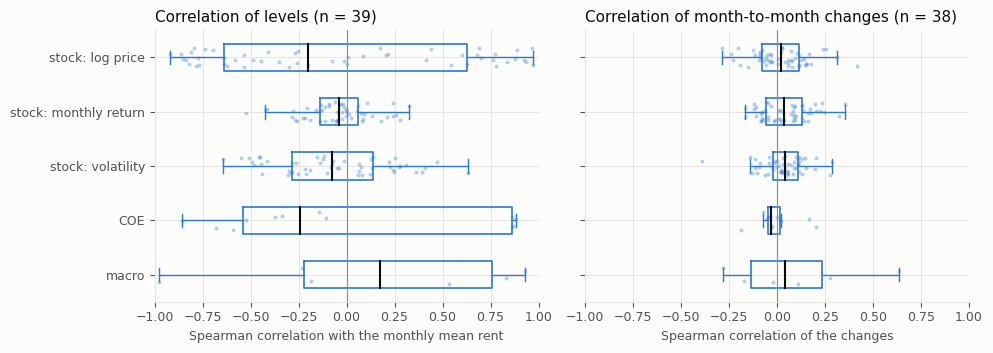

In [4]:
tab_t = pd.DataFrame(index=Z.columns)
tab_t['type'] = [temporal_type(c) for c in tab_t.index]
tab_t['rho_level'] = Z.corrwith(y, method='spearman')
tab_t['p_level'] = corr_p(tab_t['rho_level'], Z.notna().sum())
dZ, dy = Z.diff(), y.diff()
tab_t['rho_diff'] = dZ.corrwith(dy, method='spearman')
tab_t['p_diff'] = corr_p(tab_t['rho_diff'], dZ.notna().sum())
tab_t['q_diff'] = bh_fdr(tab_t['p_diff'])

summary = tab_t.groupby('type').agg(features=('rho_level', 'size'), median_abs_rho_level=('rho_level', lambda s: s.abs().median()), share_abs_rho_level_gt_05=('rho_level', lambda s: (s.abs() > 0.5).mean()),
                                    median_abs_rho_diff=('rho_diff', lambda s: s.abs().median()), significant_diff_q05=('q_diff', lambda s: int((s < 0.05).sum()))).reindex(T_TYPES)
print('by type of feature')
display(summary.round(2))
print(f'{(tab_t["rho_level"].abs() > 0.5).sum()} of {len(tab_t)} features have |rho_level| > 0.5, but only {(tab_t["q_diff"] < 0.05).sum()} of them has a significant change correlation (q < 0.05)')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, title in zip(axes, ['rho_level', 'rho_diff'], ['Correlation of levels (n = 39)', 'Correlation of month-to-month changes (n = 38)']):
    data = [tab_t.loc[tab_t['type'] == t, col].to_numpy() for t in T_TYPES]
    ax.boxplot(data, vert=False, widths=0.5, showfliers=False, medianprops=dict(color=INK, lw=1.5), boxprops=dict(color=BLUE, lw=1.2), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
    rng = np.random.default_rng(0)
    for i, d in enumerate(data, start=1):
        ax.scatter(d, i + rng.uniform(-0.18, 0.18, len(d)), s=8, color=BLUE, alpha=0.35, linewidths=0)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_xlim(-1, 1)
    ax.set_title(title)
    ax.set_xlabel('Spearman correlation with the monthly mean rent' if col == 'rho_level' else 'Spearman correlation of the changes')
axes[0].set_yticks(range(1, len(T_TYPES) + 1), T_TYPES)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## 1.2 Out-of-sample forecast skill

For each feature a line `rent = a + b x feature` is fitted on the months before a forecast origin and used to forecast the next six months from the feature values of those months (the features are known when the rent is forecast). Origins: months 21, 27 and 33.
`skill_vs_trend` = 1 - SSE(feature model) / SSE(the rent's own straight-line time trend): above 0 the feature beats extrapolating the time trend, 1 would be a perfect forecast. `skill_vs_carry` is the same against carrying the last month forward.

In [5]:
ORIGINS, HORIZON = (21, 27, 33), 6


def ols_forecast(X_tr, y_tr, X_te):
    """Simple linear regression of y on each column of X, fitted on the training rows and applied to the test rows (vectorised over the columns)."""
    mx, my = X_tr.mean(axis=0), y_tr.mean()
    var = ((X_tr - mx) ** 2).sum(axis=0)
    slope = np.divide(((X_tr - mx) * (y_tr - my)[:, None]).sum(axis=0), var, out=np.zeros_like(var), where=var > 0)
    return my + (X_te - mx) * slope


Zf = Z.fillna(0.0).to_numpy()                     # the one missing return (2021-01) is set to 0, the scaled mean, as the networks do
yv, tv = y.to_numpy(), np.arange(len(y), dtype=float)[:, None]
sse_model, sse_trend, sse_carry = np.zeros(Zf.shape[1]), 0.0, 0.0
for k in ORIGINS:
    tr, te = slice(0, k), slice(k, k + HORIZON)
    sse_model += ((ols_forecast(Zf[tr], yv[tr], Zf[te]) - yv[te][:, None]) ** 2).sum(axis=0)
    sse_trend += ((ols_forecast(tv[tr], yv[tr], tv[te]) - yv[te][:, None]) ** 2).sum()
    sse_carry += ((yv[k - 1] - yv[te]) ** 2).sum()
tab_t['skill_vs_trend'] = 1 - sse_model / sse_trend
tab_t['skill_vs_carry'] = 1 - sse_model / sse_carry
print(f'reference forecasts over the {len(ORIGINS) * HORIZON} test months: time trend RMSE ${np.sqrt(sse_trend / (len(ORIGINS) * HORIZON)):,.0f}, carry-forward RMSE ${np.sqrt(sse_carry / (len(ORIGINS) * HORIZON)):,.0f}')
print(f'{(tab_t["skill_vs_trend"] > 0).sum()} of {len(tab_t)} features beat the time trend, {(tab_t["skill_vs_carry"] > 0).sum()} beat carry-forward')
display(tab_t.groupby('type')[['skill_vs_trend', 'skill_vs_carry']].agg(['median', 'max']).reindex(T_TYPES).round(2))

reference forecasts over the 18 test months: time trend RMSE $195, carry-forward RMSE $152
0 of 177 features beat the time trend, 0 beat carry-forward


skill_vs_trend       skill_vs_carry       
                              median   max         median    max
type                                                            
stock: log price               -5.70 -0.22         -10.01  -1.00
stock: monthly return          -9.24 -7.67         -15.82 -13.24
stock: volatility              -9.13 -5.23         -15.63  -9.24
COE                            -5.39 -0.03          -9.50  -0.70
macro                          -3.90 -0.41          -7.05  -1.32

## 1.3 Multivariate selection: Lasso with time-series cross-validation

A Lasso of the standardised monthly rent on all 177 features at once, with the penalty chosen by cross-validation over four forward-chaining splits whose test blocks are six months long (the forecast horizon of 1.2). It shows which features survive when the others are present (a feature that is a copy of another one is dropped).
With 39 months the selection is fragile, so it is one vote among four, not a verdict.

In [6]:
y_std = (y - y.mean()) / y.std()
lasso = LassoCV(cv=TimeSeriesSplit(n_splits=4, test_size=6), n_alphas=100, eps=1e-4, max_iter=500_000, random_state=0).fit(Zf, y_std.to_numpy())
tab_t['lasso_coef'] = lasso.coef_
print(f'alpha {lasso.alpha_:.5f} (grid {lasso.alphas_.min():.5f}..{lasso.alphas_.max():.3f}): {(lasso.coef_ != 0).sum()} of {len(lasso.coef_)} features kept')

# the same forecasts as the single features (section 1.2), made by the Lasso at this alpha
sse_lasso = 0.0
for k in ORIGINS:
    mu, sd = yv[:k].mean(), yv[:k].std()
    fold = Lasso(alpha=lasso.alpha_, max_iter=500_000).fit(Zf[:k], (yv[:k] - mu) / sd)
    sse_lasso += ((fold.predict(Zf[k:k + HORIZON]) * sd + mu - yv[k:k + HORIZON]) ** 2).sum()
print(f'forecast skill of the Lasso on all features: {1 - sse_lasso / sse_trend:.2f} vs the time trend, {1 - sse_lasso / sse_carry:.2f} vs carry-forward (RMSE ${np.sqrt(sse_lasso / (len(ORIGINS) * HORIZON)):,.0f})')
display(tab_t.loc[tab_t['lasso_coef'] != 0, ['type', 'lasso_coef', 'rho_level', 'rho_diff']].sort_values('lasso_coef', key=np.abs, ascending=False).round(3).head(15))

alpha 0.00920 (grid 0.00010..0.964): 17 of 177 features kept
forecast skill of the Lasso on all features: -0.99 vs the time trend, -2.27 vs carry-forward (RMSE $276)


,type,lasso_coef,rho_level,rho_diff
MACRO_SORA_3M_PCT,macro,0.540,0.930,0.633
MACRO_UNEMPLOYMENT_SA_PCT,macro,-0.173,-0.975,-0.022
stk_sea_limited_log_price_mean,stock: log price,-0.073,-0.865,-0.240
stk_sheng_siong_group_log_price_mean,stock: log price,0.060,0.776,0.419
coe_c_quota_premium,COE,0.055,0.862,0.202
stk_wilmar_international_log_price_mean,stock: log price,-0.046,-0.809,0.018
stk_sembcorp_log_price_mean,stock: log price,0.030,0.970,0.112
stk_mapletree_logistics_trust_log_price_mean,stock: log price,-0.025,-0.535,0.076
stk_singtel_log_price_mean,stock: log price,0.022,0.682,0.113
stk_dbs_group_log_price_mean,stock: log price,0.011,0.836,-0.028


## 1.4 Ranking of the temporal features

`mean_rank` averages the rank of |rho_level|, |rho_diff| and `skill_vs_trend` over the 177 features (1 = best). `evidence` counts the tests passed among three that do not rest on the shared trend: a significant change correlation (q < 0.05), forecast skill above the time trend, and being kept by the Lasso.

,type,rho_level,rho_diff,q_diff,skill_vs_trend,skill_vs_carry,lasso_coef,mean_rank,evidence
MACRO_SORA_3M_PCT,macro,0.930,0.633,0.004,-0.414,-1.322,0.540,3.333,2
stk_sheng_siong_group_log_price_mean,stock: log price,0.776,0.419,0.786,-0.964,-2.226,0.060,11.000,1
stk_sea_limited_log_price_mean,stock: log price,-0.865,-0.240,0.989,-1.108,-2.462,-0.073,11.333,1
coe_c_quota_premium,COE,0.862,0.202,0.989,-0.033,-0.696,0.055,12.000,1
MACRO_PRIVATE_RENT_RPI_YOY,macro,0.830,0.276,0.989,-1.469,-3.055,0.000,13.667,0
coe_a_quota_premium,COE,0.884,0.164,0.989,-0.753,-1.879,0.000,16.333,0
stk_haw_par_log_price_mean,stock: log price,-0.794,-0.203,0.989,-1.542,-3.175,-0.000,18.667,0
stk_golden_agri_resources_log_price_mean,stock: log price,0.689,-0.289,0.989,-4.776,-8.487,0.000,23.333,0
stk_sembcorp_log_price_mean,stock: log price,0.970,0.112,0.989,-0.218,-1.001,0.030,23.333,1
stk_jardine_cycle_carriage_log_price_mean,stock: log price,0.774,0.168,0.989,-2.119,-4.123,0.000,24.500,0


features by number of tests passed (of 3): {0: 160, 1: 16, 2: 1}
type of the 25 best features: {'stock: log price': 17, 'COE': 3, 'macro': 2, 'stock: volatility': 2, 'stock: monthly return': 1}


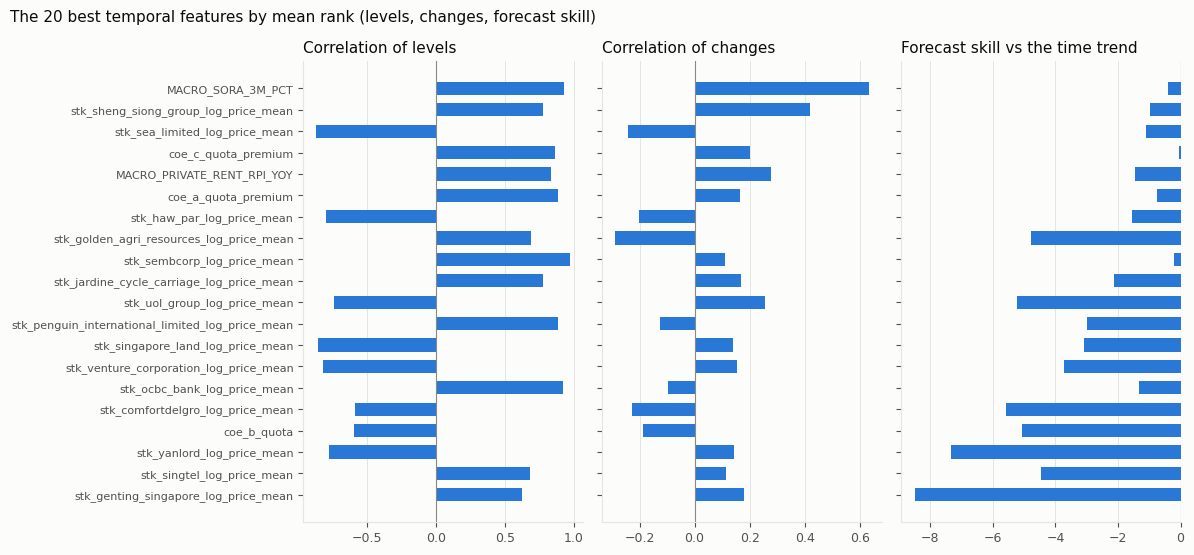

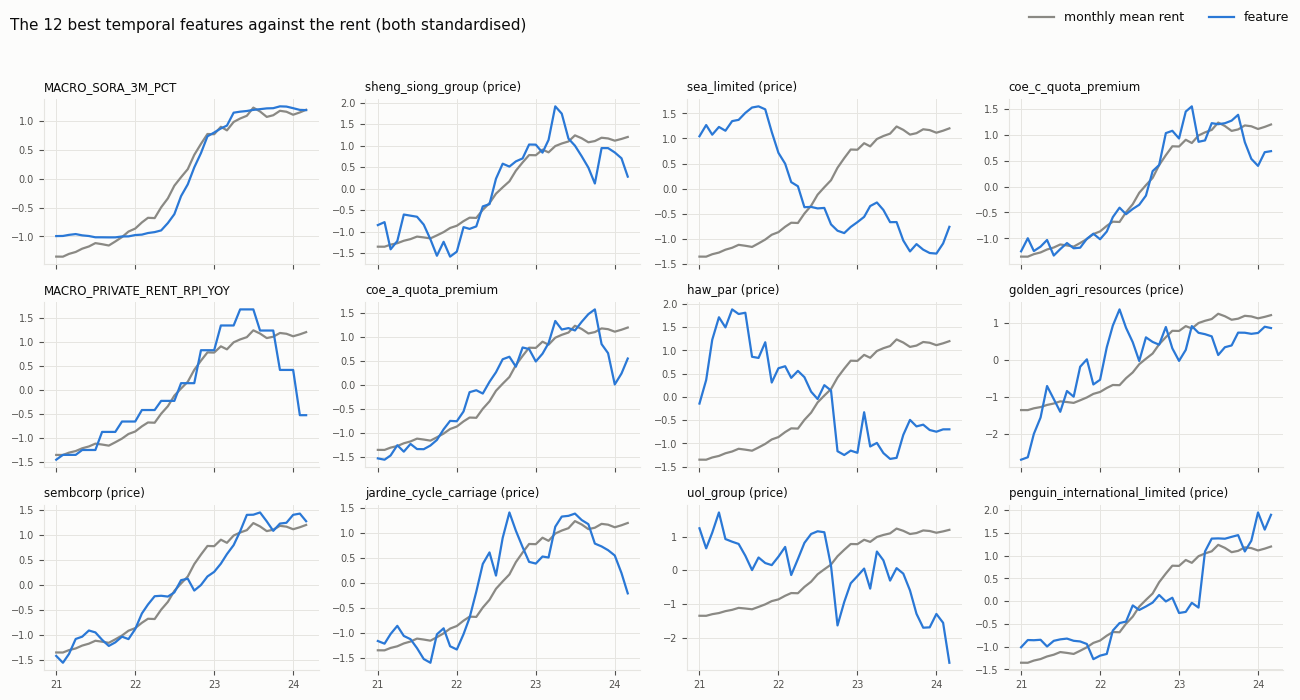

160 of 177 features pass none of the three tests, e.g. ['stk_singtel_mom_return', 'stk_netlink_trust_log_price_mean', 'stk_singapore_airlines_mom_return', 'stk_keppel_return_volatility', 'stk_moneyhero_return_volatility']


In [7]:
tab_t['mean_rank'] = pd.concat([tab_t['rho_level'].abs().rank(ascending=False), tab_t['rho_diff'].abs().rank(ascending=False), tab_t['skill_vs_trend'].rank(ascending=False)], axis=1).mean(axis=1)
tab_t['evidence'] = ((tab_t['q_diff'] < 0.05).astype(int) + (tab_t['skill_vs_trend'] > 0) + (tab_t['lasso_coef'] != 0)).astype(int)
tab_t = tab_t.sort_values('mean_rank')
save_table(tab_t, 'temporal_feature_usefulness')
cols_t = ['type', 'rho_level', 'rho_diff', 'q_diff', 'skill_vs_trend', 'skill_vs_carry', 'lasso_coef', 'mean_rank', 'evidence']
display(tab_t[cols_t].head(25).round(3))
print('features by number of tests passed (of 3):', tab_t['evidence'].value_counts().sort_index().to_dict())
print('type of the 25 best features:', tab_t.head(25)['type'].value_counts().to_dict())

top = tab_t.head(20)
fig, axes = plt.subplots(1, 3, figsize=(12, 5.6), sharey=True)
for ax, col, title in zip(axes, ['rho_level', 'rho_diff', 'skill_vs_trend'], ['Correlation of levels', 'Correlation of changes', 'Forecast skill vs the time trend']):
    ax.barh(range(len(top)), top[col], color=BLUE, height=0.62)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(top)), [f'{c}' for c in top.index], fontsize=8)
axes[0].invert_yaxis()
fig.suptitle('The 20 best temporal features by mean rank (levels, changes, forecast skill)', x=0.01, ha='left', fontsize=11)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(13, 7), sharex=True)
for ax, feature in zip(axes.ravel(), tab_t.index[:12]):
    ax.plot(dates, (y - y.mean()) / y.std(), color=MUTED, lw=1.6, label='monthly mean rent')
    ax.plot(dates, (Z[feature] - Z[feature].mean()) / Z[feature].std(), color=BLUE, lw=1.6, label='feature')
    ax.set_title(feature.replace('stk_', '').replace('_log_price_mean', ' (price)').replace('_mom_return', ' (return)').replace('_return_volatility', ' (volatility)'), fontsize=8.5)
    year_axis(ax, '%y')
    ax.tick_params(labelsize=7)
handles = [Line2D([], [], color=MUTED, lw=1.6, label='monthly mean rent'), Line2D([], [], color=BLUE, lw=1.6, label='feature')]
fig.legend(handles=handles, loc='upper right', ncol=2)
fig.suptitle('The 12 best temporal features against the rent (both standardised)', x=0.01, ha='left', fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

none_passed = tab_t[tab_t['evidence'] == 0]
print(f'{len(none_passed)} of {len(tab_t)} features pass none of the three tests, e.g. {list(none_passed.index[-5:])}')

# 2. Static features

152 features (150 of them vary on the train rows) that describe the flat and where it is: the flat itself (floor area, flat type and model, highest floor), the planning-area demographics, MRT, mall and school access, and the 47 DBSCAN location clusters (one-hot, with `-1` for noise). The numeric columns were scaled on the train rows by the data pipeline; the ordinal columns (`MAX_FLOOR`, `train_lines`, `mrt_traffic_busiest_hour`) are unscaled counts, which does not matter for the rank-based and tree-based measures used here.

Target: the **relative rent** `rent / mean rent of the month`. Every flat is compared with the market of its own month, so the upward trend of 2021-2024 does not show up as a spurious effect of features that happen to change with the sample.
The measures:

1. **Spearman correlation** with the relative rent (monotone association of a single feature).
2. **Mutual information** (k-nearest-neighbour estimate on a 30,000-row sample): any association, also non-monotone ones.
3. **Permutation importance** in a gradient-boosted model: the rise of the error on held-out months when the feature's values are shuffled. The model is fitted on the train months 0..30 and scored on months 31..38, all inside the train split, so later months are predicted from earlier ones as in the real task.
4. **Group ablations** (section 2.3): the same model refitted without a whole group of features, or with that group alone. This handles correlated features, which a single-feature permutation understates.
5. **Variance explained** by each categorical factor (eta squared, section 2.4).

In [8]:
def static_group(c):
    if c.startswith('plan_area_ft_'):
        return 'planning-area demographics'
    if c.startswith('dbscan_cluster_'):
        return 'location cluster (DBSCAN)'
    if c.startswith(('nearest_pri_school', 'pri_sch_')):
        return 'primary school'
    if c.startswith(('nearest_sec_school', 'sec_sch_')):
        return 'secondary school'
    if c.startswith(('nearest_jc_school', 'jc_')):
        return 'junior college'
    if c.startswith('nearest_school'):
        return 'nearest school (any level)'
    if c.startswith(('nearest_station', 'n_stations', 'mrt_traffic', 'train_lines', 'station_is_open')):
        return 'MRT'
    if c in ('n_malls_500m', 'nearest_mall_m'):
        return 'mall'
    if c in ('FLOOR_AREA_SQM', 'MAX_FLOOR') or c.startswith('FLAT_'):
        return 'flat'
    raise ValueError(c)


GROUPS = {}
for c in STATIC:
    GROUPS.setdefault(static_group(c), []).append(c)
print({g: len(cols) for g, cols in GROUPS.items()})

tab_s = pd.DataFrame(index=STATIC)
tab_s['group'] = [static_group(c) for c in STATIC]
tab_s['kind'] = [KIND[c] for c in STATIC]
tab_s['support'] = [train[c].mean() if KIND[c] == 'binary' else np.nan for c in STATIC]         # share of the rentals with a 1
tab_s['spearman'] = train[STATIC].corrwith(train['rel_rent'], method='spearman')
tab_s['pearson'] = train[STATIC].corrwith(train['rel_rent'])

# mutual information on a random sample of the train rows
sample = train.sample(30_000, random_state=0)
tab_s['mutual_info'] = mutual_info_regression(sample[STATIC].to_numpy(np.float64), sample['rel_rent'].to_numpy(), discrete_features=[KIND[c] == 'binary' for c in STATIC], random_state=0)
print(f'{(tab_s["support"] < 0.001).sum()} binary features cover fewer than 0.1% of the train rentals (too rare to learn from)')

{'flat': 27, 'planning-area demographics': 16, 'MRT': 12, 'mall': 2, 'nearest school (any level)': 16, 'primary school': 6, 'secondary school': 11, 'junior college': 12, 'location cluster (DBSCAN)': 48}


14 binary features cover fewer than 0.1% of the train rentals (too rare to learn from)


## 2.1 Gradient-boosted model and permutation importance

A `HistGradientBoostingRegressor` on all static features is the yardstick: how much of the variation of the relative rent do the static features explain at all (R² on the held-out months)? Permutation importance is the increase of the held-out RMSE (in units of relative rent) when one feature is shuffled, averaged over 3 shuffles.

In [9]:
FIT_LAST = 30
fit_rows, hold_rows = (train['month'] <= FIT_LAST).to_numpy(), (train['month'] > FIT_LAST).to_numpy()
Xs, ys = train[STATIC].to_numpy(np.float32), train['rel_rent'].to_numpy()
col_pos = {c: i for i, c in enumerate(STATIC)}


def fit_gbm(cols):
    idx = [col_pos[c] for c in cols]
    model = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.08, max_leaf_nodes=48, min_samples_leaf=50, l2_regularization=1.0, random_state=0)
    return model.fit(Xs[fit_rows][:, idx], ys[fit_rows]), idx


def r2(model, idx):
    pred = model.predict(Xs[hold_rows][:, idx])
    return 1 - ((ys[hold_rows] - pred) ** 2).sum() / ((ys[hold_rows] - ys[hold_rows].mean()) ** 2).sum()


def permutation_importance(model, groups, n_repeats=3, seed=0):
    """Increase of the held-out RMSE when the columns of a group are shuffled together (the same row permutation for all its columns)."""
    rng = np.random.default_rng(seed)
    X, target = Xs[hold_rows].copy(), ys[hold_rows]
    base = rmse(target, model.predict(X))
    out = {}
    for name, cols in groups.items():
        idx = [col_pos[c] for c in cols]
        original = X[:, idx].copy()
        scores = []
        for _ in range(n_repeats):
            X[:, idx] = original[rng.permutation(len(X))]
            scores.append(rmse(target, model.predict(X)) - base)
        X[:, idx] = original
        out[name] = (np.mean(scores), np.std(scores))
    return pd.DataFrame(out, index=['mean', 'sd']).T, base


gbm, all_idx = fit_gbm(STATIC)
perm, base_rmse = permutation_importance(gbm, {c: [c] for c in STATIC})
tab_s['perm_importance'] = perm['mean']
tab_s['perm_sd'] = perm['sd']
r2_full = r2(gbm, all_idx)
print(f'held-out months {FIT_LAST + 1}..{train["month"].max()} ({hold_rows.sum():,} rentals): R² of the relative rent {r2_full:.3f}, RMSE {base_rmse:.4f} (a constant prediction: {ys[hold_rows].std():.4f})')

held-out months 31..38 (23,698 rentals): R² of the relative rent 0.390, RMSE 0.1807 (a constant prediction: 0.2313)


## 2.2 Ranking of the static features

`mean_rank` averages the ranks of |Spearman|, mutual information and permutation importance (1 = best). Many features of one group are copies of each other (all demographics of a planning area are the same for all its blocks), so the importance of a group is shared among its members: read the single-feature ranking together with the group ablations of 2.3.
The planning-area demographics also show a high mutual information next to a small correlation: they take only 31 distinct values, one per planning area, so they work as an area label whose effect is not monotone.

,group,kind,spearman,mutual_info,perm_importance,perm_sd,mean_rank
FLOOR_AREA_SQM,flat,numeric,0.4087,0.1350,0.0580,0.0006,1.0000
MAX_FLOOR,flat,ordinal,0.2747,0.0744,0.0069,0.0001,3.0000
FLAT_TYPE_3 room,flat,binary,-0.3892,0.0989,0.0002,0.0001,8.0000
plan_area_ft_pct_age_15_64,planning-area demographics,numeric,-0.0678,0.0546,0.0020,0.0001,14.3333
nearest_mall_m,mall,numeric,-0.0633,0.0573,0.0006,0.0000,14.3333
plan_area_ft_pct_pmet,planning-area demographics,numeric,0.0908,0.0516,0.0004,0.0000,15.3333
FLAT_TYPE_4 room,flat,binary,0.1431,0.0119,0.0072,0.0001,17.0000
nearest_station_m,MRT,numeric,-0.1126,0.0140,0.0020,0.0001,17.6667
FLAT_MODEL_new generation,flat,binary,-0.1811,0.0229,0.0002,0.0000,18.0000
FLAT_TYPE_2 room,flat,binary,-0.1717,0.0200,0.0002,0.0000,19.0000


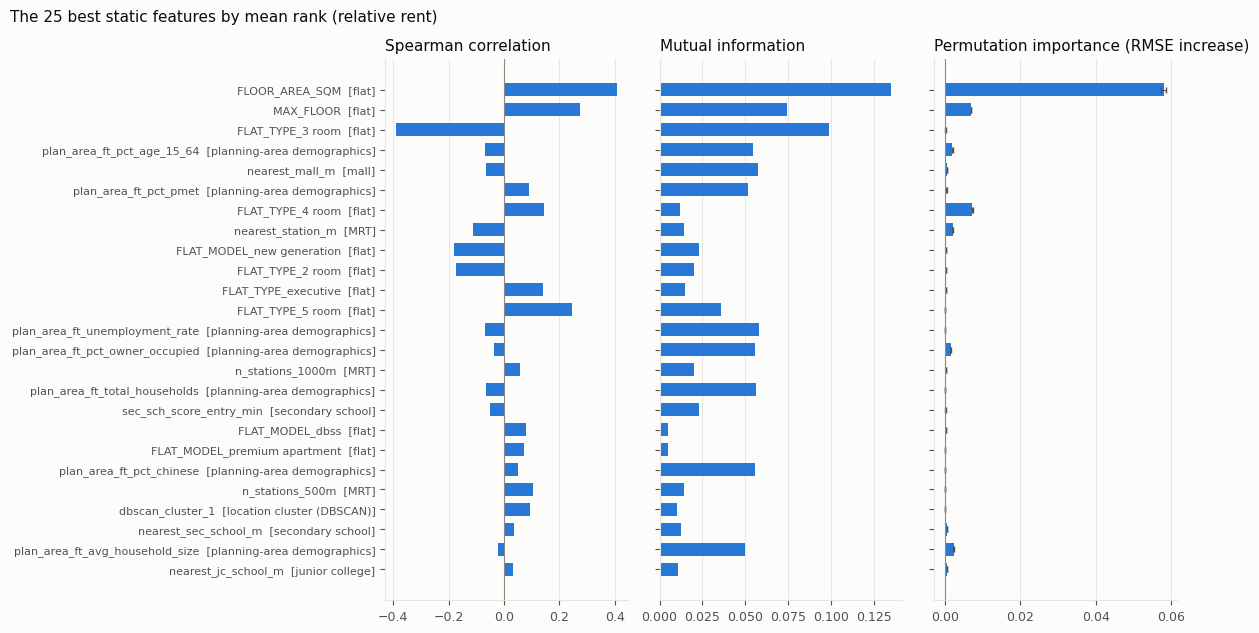

18 of 150 features have no measurable signal (permutation importance <= 0 and |Spearman| < 0.01); 63 have a non-positive permutation importance


,features,best_feature,best_abs_spearman,best_perm_importance
group,,,,
MRT,12,nearest_station_m,0.1126,0.0020
flat,27,FLOOR_AREA_SQM,0.4087,0.0580
junior college,12,nearest_jc_school_m,0.0771,0.0006
location cluster (DBSCAN),48,dbscan_cluster_1,0.0935,0.0001
mall,2,nearest_mall_m,0.0633,0.0006
nearest school (any level),16,nearest_school_m,0.0482,0.0003
planning-area demographics,16,plan_area_ft_pct_age_15_64,0.0908,0.0023
primary school,6,nearest_pri_school_m,0.0096,0.0004
secondary school,11,sec_sch_score_entry_min,0.0521,0.0005


In [10]:
tab_s['mean_rank'] = pd.concat([tab_s['spearman'].abs().rank(ascending=False), tab_s['mutual_info'].rank(ascending=False), tab_s['perm_importance'].rank(ascending=False)], axis=1).mean(axis=1)
tab_s = tab_s.sort_values('mean_rank')
save_table(tab_s, 'static_feature_usefulness')
cols_s = ['group', 'kind', 'spearman', 'mutual_info', 'perm_importance', 'perm_sd', 'mean_rank']
display(tab_s[cols_s].head(30).round(4))

top = tab_s.head(25)
fig, axes = plt.subplots(1, 3, figsize=(12, 6.4), sharey=True)
for ax, col, title in zip(axes, ['spearman', 'mutual_info', 'perm_importance'], ['Spearman correlation', 'Mutual information', 'Permutation importance (RMSE increase)']):
    ax.barh(range(len(top)), top[col], color=BLUE, height=0.62)
    if col == 'perm_importance':
        ax.errorbar(top[col], range(len(top)), xerr=top['perm_sd'], fmt='none', ecolor=INK2, elinewidth=0.8, capsize=2)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(top)), [f'{c}  [{g}]' for c, g in zip(top.index, top['group'])], fontsize=8)
axes[0].invert_yaxis()
fig.suptitle('The 25 best static features by mean rank (relative rent)', x=0.01, ha='left', fontsize=11)
plt.tight_layout()
plt.show()

useless = tab_s[(tab_s['perm_importance'] <= 0) & (tab_s['spearman'].abs() < 0.01)]
print(f'{len(useless)} of {len(tab_s)} features have no measurable signal (permutation importance <= 0 and |Spearman| < 0.01); {int((tab_s["perm_importance"] <= 0).sum())} have a non-positive permutation importance')
display(tab_s.groupby('group').agg(features=('kind', 'size'), best_feature=('mean_rank', lambda s: s.idxmin()), best_abs_spearman=('spearman', lambda s: s.abs().max()), best_perm_importance=('perm_importance', 'max')).round(4))

## 2.3 Importance of whole groups

For each group of features, the gradient-boosted model is refitted **without** it (the loss of R² is what the rest cannot replace) and **with it alone** (what the group explains by itself). The group permutation importance shuffles the group's columns together.
A group whose loss is small but whose "alone" R² is large is redundant with others (e.g. the demographics and the cluster features both encode the area), not useless.

,features,r2_alone,r2_loss_when_removed,perm_importance
group,,,,
flat,27,0.3451,0.1151,0.0802
MRT,12,0.2119,-0.0004,0.0030
secondary school,11,0.1686,0.0005,0.0008
junior college,12,0.1533,0.0018,0.0007
mall,2,0.0872,0.0024,0.0005
nearest school (any level),16,0.0694,-0.0005,0.0004
location cluster (DBSCAN),48,0.0531,0.0015,0.0002
planning-area demographics,16,0.0495,-0.0001,0.0193
primary school,6,0.0364,-0.0003,0.0004


all 150 static features together: held-out R² 0.390


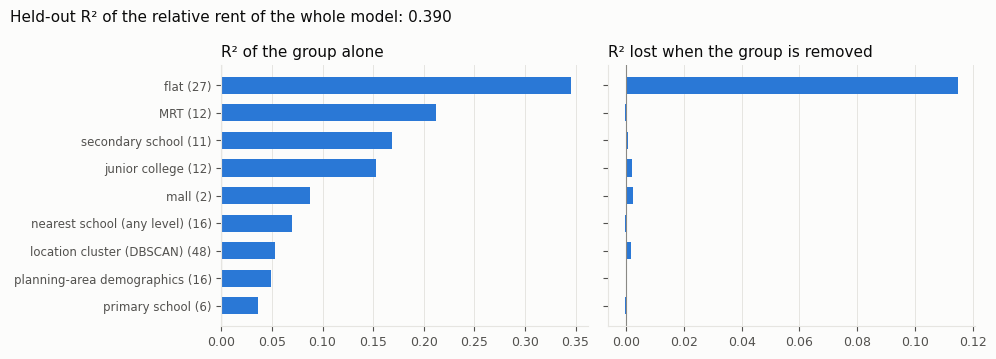

In [11]:
rows = []
group_perm, _ = permutation_importance(gbm, GROUPS)
for g, cols in GROUPS.items():
    rest = [c for c in STATIC if c not in cols]
    m_without, i_without = fit_gbm(rest)
    m_alone, i_alone = fit_gbm(cols)
    rows.append({'group': g, 'features': len(cols), 'r2_alone': r2(m_alone, i_alone), 'r2_loss_when_removed': r2_full - r2(m_without, i_without), 'perm_importance': group_perm.loc[g, 'mean']})
tab_g = pd.DataFrame(rows).set_index('group').sort_values('r2_alone', ascending=False)
display(tab_g.round(4))
print(f'all {len(STATIC)} static features together: held-out R² {r2_full:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, title in zip(axes, ['r2_alone', 'r2_loss_when_removed'], ['R² of the group alone', 'R² lost when the group is removed']):
    ax.barh(range(len(tab_g)), tab_g[col], color=BLUE, height=0.62)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(tab_g)), [f'{g} ({n})' for g, n in zip(tab_g.index, tab_g['features'])], fontsize=8.5)
axes[0].invert_yaxis()
fig.suptitle(f'Held-out R² of the relative rent of the whole model: {r2_full:.3f}', x=0.01, ha='left', fontsize=11)
plt.tight_layout()
plt.show()

## 2.4 Variance explained by each categorical factor

The one-hot columns are decoded back into the factors they come from. Eta squared is the share of the variance of the rent explained by the factor alone; the adjusted value subtracts what a factor with that many levels would explain by chance. Reported for the raw rent and for the relative rent.

,levels,eta2_relative_rent,adj_eta2_relative_rent,eta2_rent,adj_eta2_rent
factor,,,,,
flat type,6,0.205,0.205,0.124,0.124
flat model,19,0.086,0.086,0.060,0.060
DBSCAN cluster,48,0.057,0.056,0.037,0.037
junior college: type,4,0.011,0.011,0.007,0.007
junior college: nature,3,0.003,0.003,0.002,0.002
nearest school: type,5,0.003,0.003,0.002,0.002
secondary school: type,5,0.003,0.003,0.001,0.001
nearest school: level,7,0.002,0.002,0.001,0.001
nearest school: nature,3,0.001,0.001,0.001,0.001


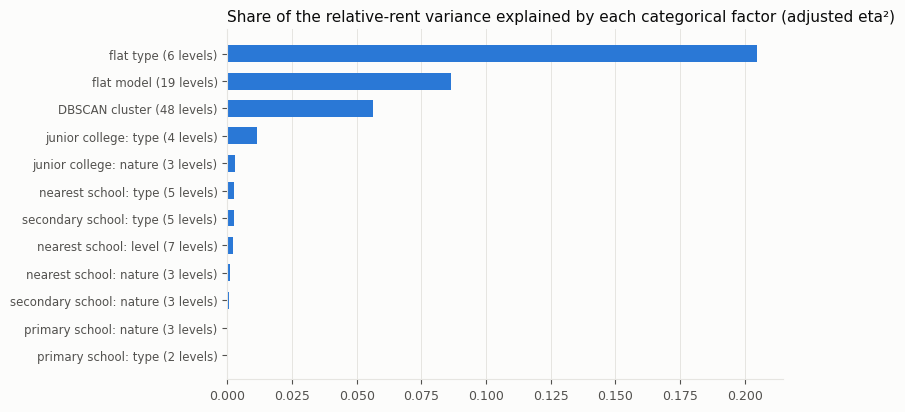

In [12]:
FACTORS = {'FLAT_TYPE_': 'flat type', 'FLAT_MODEL_': 'flat model', 'dbscan_cluster_': 'DBSCAN cluster', 'nearest_school_type_': 'nearest school: type', 'nearest_school_nature_': 'nearest school: nature',
           'nearest_school_level_': 'nearest school: level', 'pri_sch_type_': 'primary school: type', 'pri_sch_nature_': 'primary school: nature', 'sec_sch_type_': 'secondary school: type',
           'sec_sch_nature_': 'secondary school: nature', 'jc_sch_type_': 'junior college: type', 'jc_sch_nature_': 'junior college: nature'}


def decode(prefix):
    block = train[[c for c in HOT_COL if c.startswith(prefix)]]
    label = block.idxmax(axis=1).str[len(prefix):]
    return label.where(block.sum(axis=1) > 0, '(none)')


def eta_squared(target, labels):
    """(eta², adjusted eta²) of a target explained by the levels of a factor."""
    g = target.groupby(labels.to_numpy())
    mean = target.mean()
    eta = (g.size() * (g.mean() - mean) ** 2).sum() / ((target - mean) ** 2).sum()
    n, k = len(target), g.ngroups
    return eta, 1 - (1 - eta) * (n - 1) / (n - k)


def eta_table(factors):
    rows = []
    for name, labels in factors.items():
        e_rel, a_rel = eta_squared(train['rel_rent'], labels)
        e_raw, a_raw = eta_squared(train[LABEL], labels)
        rows.append({'factor': name, 'levels': labels.nunique(), 'eta2_relative_rent': e_rel, 'adj_eta2_relative_rent': a_rel, 'eta2_rent': e_raw, 'adj_eta2_rent': a_raw})
    return pd.DataFrame(rows).set_index('factor').sort_values('adj_eta2_relative_rent', ascending=False)


tab_f = eta_table({name: decode(prefix) for prefix, name in FACTORS.items()})
display(tab_f.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(range(len(tab_f)), tab_f['adj_eta2_relative_rent'], color=BLUE, height=0.62)
ax.set_yticks(range(len(tab_f)), [f'{n} ({k} levels)' for n, k in zip(tab_f.index, tab_f['levels'])], fontsize=8.5)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_title('Share of the relative-rent variance explained by each categorical factor (adjusted eta²)')
plt.tight_layout()
plt.show()

# 3. DBSCAN location clusters and the rent

`data/features/cleaned/static_features/location_cluster` assigns every block to a DBSCAN cluster of its coordinates (47 clusters, and `-1` for 226 rentals of isolated blocks that are noise). The cluster enters the models as one-hot columns.
The maps place the blocks of the train rentals on the outline of the planning areas. A categorical colour cannot carry 47 clusters, so the clusters are marked by their id at the centre of their blocks and the rent is carried by a one-hue (price) and a two-hue (relative to the month) scale.

In [13]:
train['cluster'] = decode('dbscan_cluster_').astype(int)
train['block'] = train['TOWN'] + ' | ' + train['BLOCK'].astype(str) + ' | ' + train['STREET']          # POSTAL_CODE is 'NIL' for 284 blocks, so it is not a key
blocks = train.groupby('block').agg(lat=('LATITUDE', 'first'), lon=('LONGITUDE', 'first'), cluster=('cluster', 'first'), n=(LABEL, 'size'), rent=(LABEL, 'mean'), rel_rent=('rel_rent', 'mean'),
                                            town=('TOWN', 'first'), planning_area=('PLANNING_AREA', 'first'))
assert train.groupby('block')['cluster'].nunique().max() == 1

# the one-hot columns must agree with the cluster file of the data pipeline
file = pd.read_csv(CLUSTER_FILE, dtype={'BLOCK': str})
file = file.assign(block=file['TOWN'] + ' | ' + file['BLOCK'] + ' | ' + file['STREET']).drop_duplicates('block').set_index('block')['dbscan_cluster']
common = blocks.index.intersection(file.index)
print(f'{len(blocks):,} blocks, {len(common):,} found in the cluster file; clusters that differ from the file: {(blocks.loc[common, "cluster"] != file.loc[common]).sum()}')

stats_c = train.groupby('cluster').agg(rentals=(LABEL, 'size'), blocks=('block', 'nunique'), median_rent=(LABEL, 'median'), q25=(LABEL, lambda s: s.quantile(0.25)), q75=(LABEL, lambda s: s.quantile(0.75)),
                                      mean_rel_rent=('rel_rent', 'mean'), sd_rel_rent=('rel_rent', 'std'))
stats_c['lat'] = blocks.groupby('cluster')['lat'].mean()
stats_c['lon'] = blocks.groupby('cluster')['lon'].mean()
stats_c['towns'] = train.groupby('cluster')['TOWN'].agg(lambda s: ', '.join(s.value_counts().index[:2]))

with open(GEOJSON) as f:
    geo = json.load(f)


def outlines(ax):
    for feature in geo['features']:
        geom = feature['geometry']
        polygons = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        for polygon in polygons:
            ring = np.array(polygon[0])[:, :2]
            ax.plot(ring[:, 0], ring[:, 1], color=MUTED, lw=0.5, alpha=0.7)
    ax.set_xlim(103.60, 104.05)
    ax.set_ylim(1.22, 1.48)
    ax.set_aspect(1.0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

9,314 blocks, 9,314 found in the cluster file; clusters that differ from the file: 0


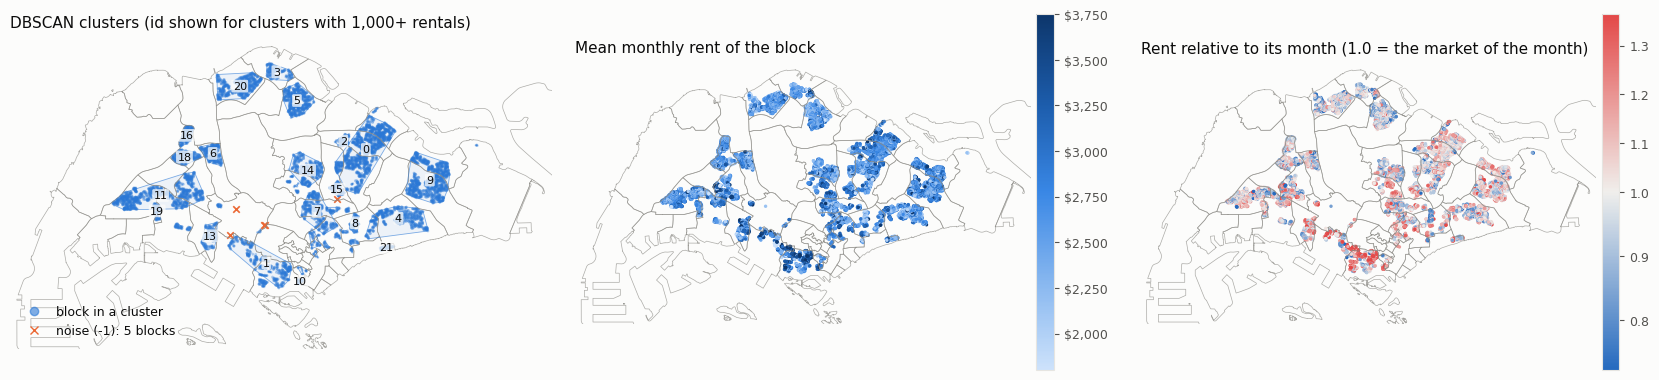

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2))
ax = axes[0]
outlines(ax)
clustered, noise = blocks[blocks['cluster'] >= 0], blocks[blocks['cluster'] < 0]
for cid, grp in clustered.groupby('cluster'):
    if len(grp) >= 3:
        pts = grp[['lon', 'lat']].to_numpy()
        try:
            hull = pts[ConvexHull(pts).vertices]
            ax.fill(hull[:, 0], hull[:, 1], color=BLUE, alpha=0.07, lw=0)
            ax.plot(*np.vstack([hull, hull[:1]]).T, color=BLUE, lw=0.6, alpha=0.6)
        except Exception:
            pass
ax.scatter(clustered['lon'], clustered['lat'], s=4 + 0 * clustered['n'], color=BLUE, alpha=0.35, linewidths=0)
ax.scatter(noise['lon'], noise['lat'], s=22, marker='x', color=ORANGE, linewidths=1.2)
for cid, r in stats_c.iterrows():
    if cid >= 0 and r['rentals'] >= 1000:
        ax.annotate(str(cid), (r['lon'], r['lat']), fontsize=8, ha='center', va='center', color=INK, bbox=dict(boxstyle='round,pad=0.12', fc=SURFACE, ec='none', alpha=0.75))
ax.set_title('DBSCAN clusters (id shown for clusters with 1,000+ rentals)')
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=BLUE, alpha=0.6, label='block in a cluster'), Line2D([], [], marker='x', ls='', color=ORANGE, label=f'noise (-1): {len(noise)} blocks')], loc='lower left')

ax = axes[1]
outlines(ax)
sc = ax.scatter(blocks['lon'], blocks['lat'], c=blocks['rent'], cmap=SEQ, s=6, linewidths=0, vmin=blocks['rent'].quantile(0.02), vmax=blocks['rent'].quantile(0.98))
cb = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.01)
cb.formatter = '${x:,.0f}'
cb.update_ticks()
ax.set_title('Mean monthly rent of the block')

ax = axes[2]
outlines(ax)
sc = ax.scatter(blocks['lon'], blocks['lat'], c=blocks['rel_rent'], cmap=DIV, norm=TwoSlopeNorm(1.0, blocks['rel_rent'].quantile(0.02), blocks['rel_rent'].quantile(0.98)), s=6, linewidths=0)
fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.01)
ax.set_title('Rent relative to its month (1.0 = the market of the month)')
plt.tight_layout()
plt.show()

## 3.1 Rent by cluster

Clusters are ranked by the median rent of their rentals. The bars show the interquartile range of the raw rent; the right panel shows the mean relative rent, which removes the trend and is the part a location feature can explain. Clusters differ in size and in the mix of flat types, so the raw rent differs more between clusters than the relative rent does.

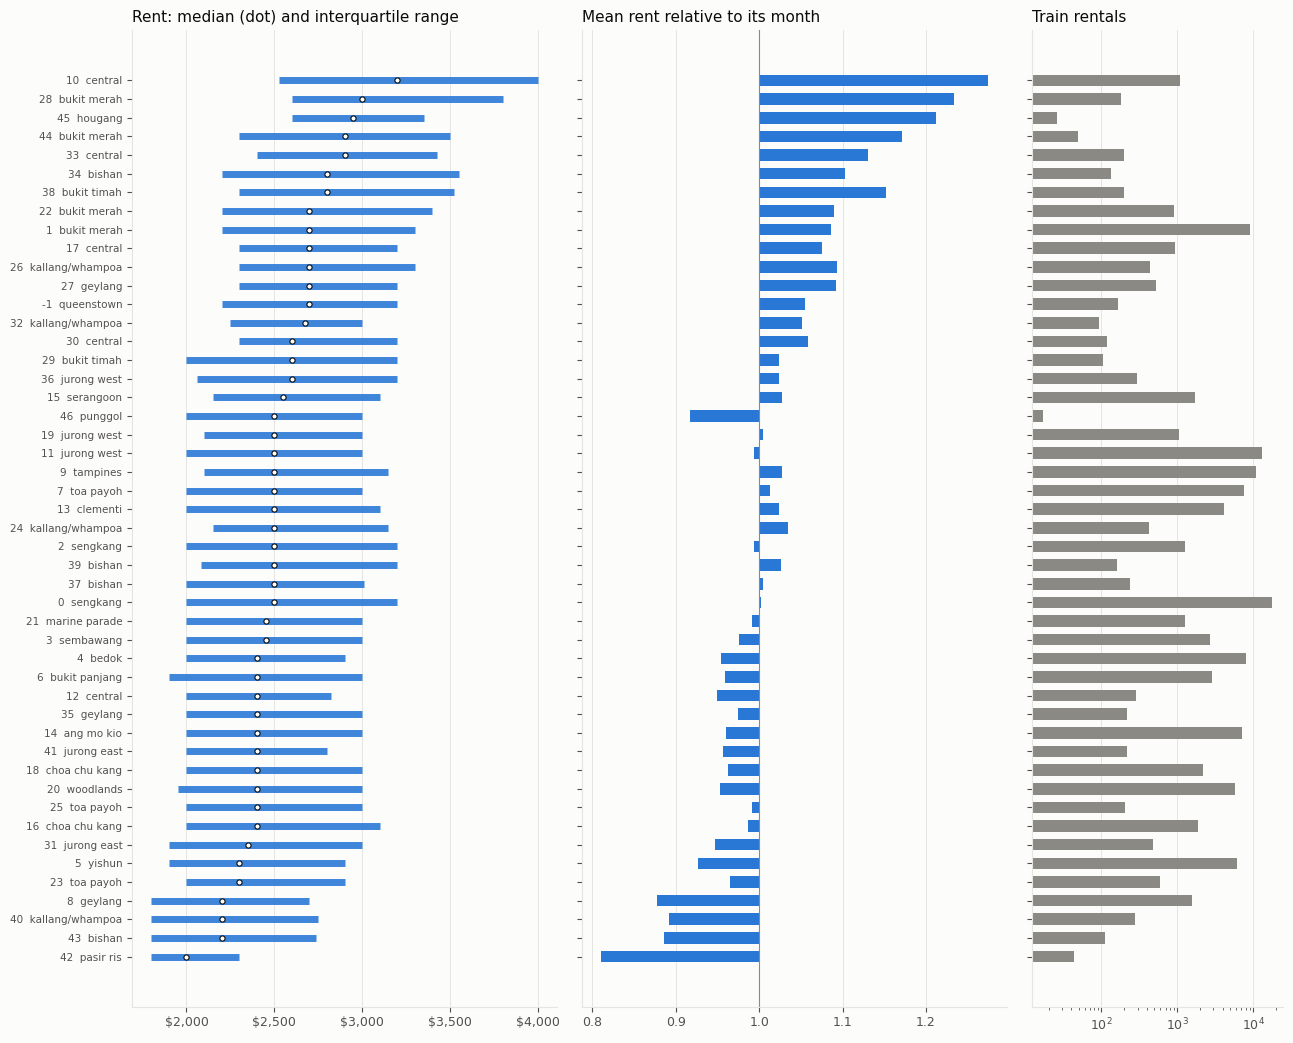

,rentals,blocks,median_rent,mean_rel_rent,sd_rel_rent,towns
cluster,,,,,,
10,1075,30,3200.0,1.274,0.299,"central, bukit merah"
28,180,16,3000.0,1.234,0.211,bukit merah
45,26,3,2950.0,1.213,0.240,hougang
44,49,5,2900.0,1.172,0.243,bukit merah
38,196,19,2800.0,1.152,0.273,bukit timah
33,199,10,2900.0,1.131,0.199,"central, kallang/whampoa"
34,135,14,2800.0,1.103,0.214,bishan
26,442,22,2700.0,1.093,0.251,kallang/whampoa


,rentals,blocks,median_rent,mean_rel_rent,sd_rel_rent,towns
cluster,,,,,,
42,43,3,2000.0,0.810,0.143,pasir ris
8,1575,106,2200.0,0.877,0.231,geylang
43,110,4,2200.0,0.885,0.167,bishan
40,277,12,2200.0,0.892,0.250,kallang/whampoa
46,17,9,2500.0,0.917,0.301,punggol
5,6100,605,2300.0,0.927,0.196,yishun
31,475,36,2350.0,0.947,0.224,jurong east
12,283,10,2400.0,0.949,0.235,central


In [15]:
order = stats_c.sort_values('median_rent').index
fig, axes = plt.subplots(1, 3, figsize=(13, 10.5), sharey=True, gridspec_kw={'width_ratios': [2.2, 2.2, 1.3]})
pos = np.arange(len(order))
ax = axes[0]
ax.hlines(pos, stats_c.loc[order, 'q25'], stats_c.loc[order, 'q75'], color=BLUE, lw=5, alpha=0.9)
ax.scatter(stats_c.loc[order, 'median_rent'], pos, color=SURFACE, edgecolor=INK, s=14, zorder=3, linewidths=0.8)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Rent: median (dot) and interquartile range')
ax = axes[1]
ax.barh(pos, stats_c.loc[order, 'mean_rel_rent'] - 1, left=1, color=BLUE, height=0.62)
ax.axvline(1, color=MUTED, lw=0.8)
ax.set_title('Mean rent relative to its month')
ax = axes[2]
ax.barh(pos, stats_c.loc[order, 'rentals'], color=MUTED, height=0.62)
ax.set_title('Train rentals')
ax.set_xscale('log')
axes[0].set_yticks(pos, [f'{c}  {stats_c.loc[c, "towns"].split(",")[0]}' for c in order], fontsize=7.5)
for a in axes:
    a.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()
display(stats_c.sort_values('mean_rel_rent', ascending=False)[['rentals', 'blocks', 'median_rent', 'mean_rel_rent', 'sd_rel_rent', 'towns']].round(3).head(8))
display(stats_c.sort_values('mean_rel_rent')[['rentals', 'blocks', 'median_rent', 'mean_rel_rent', 'sd_rel_rent', 'towns']].round(3).head(8))

## 3.2 Do the clusters add information over the administrative areas?

Share of the variance of the rent explained by the cluster compared with region, planning area, town and subzone, and with the block itself, which is the **ceiling** of any location feature (a model that knew each block's average). Adjusted eta squared, so that finer divisions are not credited for their number of levels.
The cluster is useful if it explains about as much as the planning areas with far fewer levels, or more than they do.

,levels,eta2_relative_rent,adj_eta2_relative_rent,eta2_rent,adj_eta2_rent
factor,,,,,
region,5,0.021,0.021,0.013,0.013
town,26,0.055,0.055,0.036,0.035
planning area,31,0.058,0.057,0.038,0.037
DBSCAN cluster,48,0.057,0.056,0.037,0.037
subzone,156,0.136,0.135,0.090,0.089
block (ceiling),9314,0.418,0.367,0.296,0.234


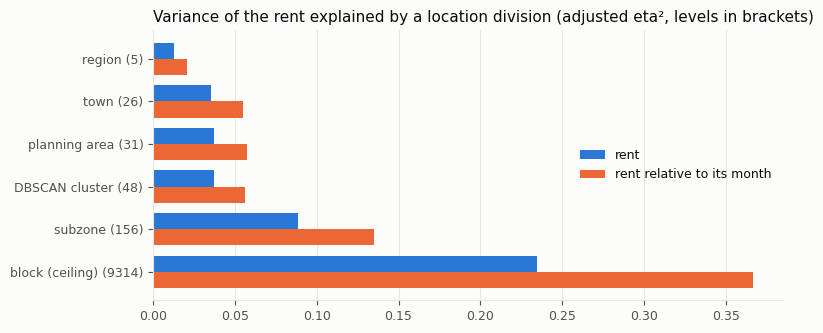

relative rent: planning area alone 0.057 (adjusted), planning area x cluster 0.073 (67 combinations)


In [16]:
admin = {'region': train['REGION'], 'planning area': train['PLANNING_AREA'], 'town': train['TOWN'], 'subzone': train['SUBZONE'], 'DBSCAN cluster': train['cluster'].astype(str), 'block (ceiling)': train['block']}
tab_a = eta_table(admin).sort_values('levels')
display(tab_a.round(3))

fig, ax = plt.subplots(figsize=(8, 3.4))
height = 0.38
pos = np.arange(len(tab_a))
ax.barh(pos - height / 2, tab_a['adj_eta2_rent'], height=height, color=BLUE, label='rent')
ax.barh(pos + height / 2, tab_a['adj_eta2_relative_rent'], height=height, color=ORANGE, label='rent relative to its month')
ax.set_yticks(pos, [f'{n} ({k})' for n, k in zip(tab_a.index, tab_a['levels'])])
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(loc='center right')
ax.set_title('Variance of the rent explained by a location division (adjusted eta², levels in brackets)')
plt.tight_layout()
plt.show()

# does the cluster add anything to the planning area? nested view: the part of the variance of the relative rent the cluster explains inside the planning areas
inside = train.assign(pa_cluster=train['PLANNING_AREA'] + '|' + train['cluster'].astype(str))
e_pa, a_pa = eta_squared(train['rel_rent'], train['PLANNING_AREA'])
e_pc, a_pc = eta_squared(train['rel_rent'], inside['pa_cluster'])
print(f'relative rent: planning area alone {a_pa:.3f} (adjusted), planning area x cluster {a_pc:.3f} ({inside["pa_cluster"].nunique()} combinations)')

# 4. Correlation and similarity

Spearman correlation is used throughout (rank-based, so insensitive to the skew of the distance features and meaningful for the 0/1 columns). Features are grouped into **families** by hierarchical clustering on the distance `1 - |correlation|` (average linkage): two features end up in one family when they are, on average, correlated at `|rho| >= FAMILY_RHO`. From each family the feature with the best `mean_rank` of the sections above is suggested as its representative; the rest are candidates for removal when a smaller feature set is wanted.

In [17]:
FAMILY_RHO = 0.90


def linkage_of(corr):
    dist = 1 - corr.abs().to_numpy()
    dist = (dist + dist.T) / 2
    np.fill_diagonal(dist, 0)
    return hierarchy.linkage(squareform(dist, checks=False), method='average')


def families(corr, ranking, threshold=FAMILY_RHO):
    """Table of the multi-feature families: members, size, the representative (best mean rank) and the lowest within-family |correlation|."""
    labels = hierarchy.fcluster(linkage_of(corr), t=1 - threshold, criterion='distance')
    rows = []
    for fam in np.unique(labels):
        members = list(corr.columns[labels == fam])
        if len(members) < 2:
            continue
        rep = ranking.loc[members, 'mean_rank'].idxmin()
        sub = corr.loc[members, members].abs().to_numpy()
        rows.append({'size': len(members), 'representative': rep, 'min_abs_rho': sub[np.triu_indices(len(members), 1)].min(), 'members': members})
    table = pd.DataFrame(rows).sort_values('size', ascending=False).reset_index(drop=True)
    table.index.name = 'family'
    return table, labels


def top_pairs(corr, k=25, skip=lambda a, b: False):
    """The k most correlated pairs of features (by |rho|)."""
    iu = np.triu_indices(len(corr), 1)
    pairs = pd.DataFrame({'feature_a': corr.columns[iu[0]], 'feature_b': corr.columns[iu[1]], 'rho': corr.to_numpy()[iu]})
    pairs = pairs[[not skip(a, b) for a, b in zip(pairs['feature_a'], pairs['feature_b'])]]
    return pairs.reindex(pairs['rho'].abs().sort_values(ascending=False).index).head(k).reset_index(drop=True)


def similar_to(corr, feature, k=8):
    """The k features most correlated (by |rho|) with a feature."""
    s = corr[feature].drop(feature)
    return s.reindex(s.abs().sort_values(ascending=False).index).head(k).rename('rho').to_frame()

## 4.1 Temporal features

Correlation over the 39 train months. The heatmap is ordered by the hierarchical clustering; the strip on the left gives the type of each feature. Features of the same stock family (price, return, volatility) are not necessarily neighbours: stocks move together with the market, so the price levels of unrelated stocks are strongly correlated.

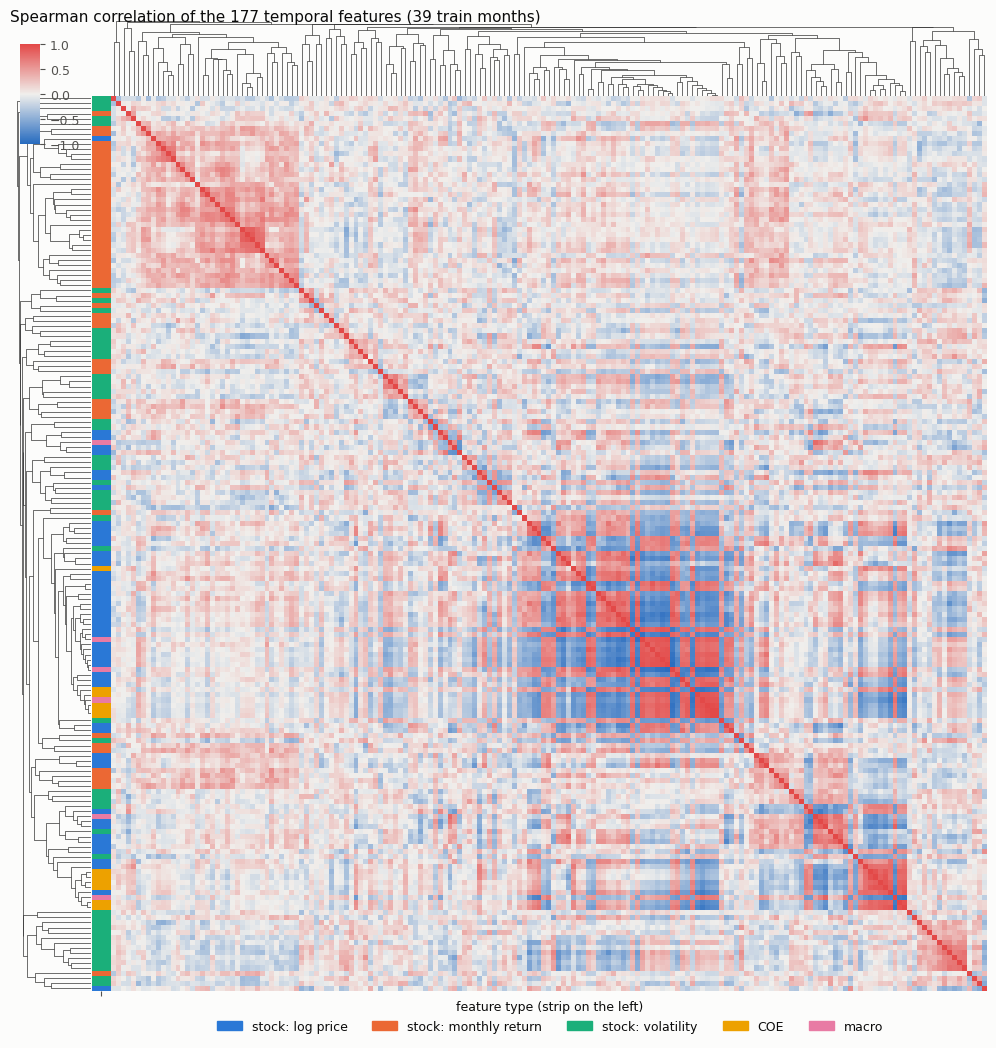

15,576 feature pairs: 0.2% have |rho| > 0.9, 2.9% have |rho| > 0.7, median |rho| 0.17


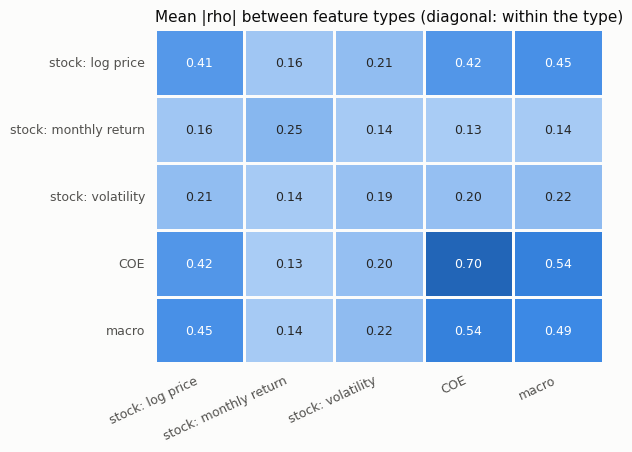

In [18]:
corr_t = Z.corr(method='spearman')
link_t = linkage_of(corr_t)
strip = pd.Series([T_COLOUR[temporal_type(c)] for c in corr_t.columns], index=corr_t.columns)
g = sns.clustermap(corr_t, row_linkage=link_t, col_linkage=link_t, cmap=DIV, vmin=-1, vmax=1, center=0, row_colors=strip, figsize=(10, 10), xticklabels=False, yticklabels=False,
                   dendrogram_ratio=(0.08, 0.08), cbar_pos=(0.02, 0.86, 0.02, 0.1), colors_ratio=0.02)
g.ax_heatmap.set_xlabel('')
g.ax_heatmap.set_ylabel('')
g.fig.legend(handles=[Patch(color=T_COLOUR[t], label=t) for t in T_TYPES], loc='lower center', ncol=len(T_TYPES), bbox_to_anchor=(0.55, -0.04), title='feature type (strip on the left)')
g.fig.suptitle('Spearman correlation of the 177 temporal features (39 train months)', x=0.01, y=0.995, ha='left', fontsize=11)
plt.show()

iu = np.triu_indices(len(corr_t), 1)
abs_pairs = corr_t.abs().to_numpy()[iu]
print(f'{len(abs_pairs):,} feature pairs: {(abs_pairs > 0.9).mean():.1%} have |rho| > 0.9, {(abs_pairs > 0.7).mean():.1%} have |rho| > 0.7, median |rho| {np.median(abs_pairs):.2f}')

type_of = pd.Series([temporal_type(c) for c in corr_t.columns], index=corr_t.columns)
between = pd.DataFrame(index=T_TYPES, columns=T_TYPES, dtype=float)
for a in T_TYPES:
    for b in T_TYPES:
        sub = corr_t.abs().loc[type_of == a, type_of == b].to_numpy()
        between.loc[a, b] = sub[~np.eye(*sub.shape, dtype=bool)].mean() if a == b else sub.mean()
fig, ax = plt.subplots(figsize=(6.2, 4.6))
sns.heatmap(between, annot=True, fmt='.2f', cmap=SEQ, vmin=0, vmax=1, cbar=False, ax=ax, linewidths=2, linecolor=SURFACE, annot_kws=dict(fontsize=9))
ax.set_title('Mean |rho| between feature types (diagonal: within the type)')
ax.tick_params(left=False, bottom=False)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [19]:
fam_t, labels_t = families(corr_t, tab_t)
print(f'{len(corr_t)} temporal features fall into {len(np.unique(labels_t))} families at |rho| >= {FAMILY_RHO}: {len(fam_t)} families have several members ({fam_t["size"].sum()} features), {(np.bincount(labels_t) == 1).sum()} features stand alone')
display(fam_t.assign(members=fam_t['members'].map(lambda m: ', '.join(x.replace('stk_', '') for x in m[:6]) + (f' ... (+{len(m) - 6})' if len(m) > 6 else ''))).head(12))
save_table(fam_t.assign(members=fam_t['members'].map('; '.join)), 'temporal_feature_families')

print('most correlated pairs of temporal features')
display(top_pairs(corr_t, 15).round(3))
print('the features most similar to the best temporal feature,', tab_t.index[0])
display(similar_to(corr_t, tab_t.index[0]).round(3))

# effective dimensionality: the 39 train months cannot span more than 38 directions
pca_t = PCA().fit(Z.fillna(0.0))
cum_t = np.cumsum(pca_t.explained_variance_ratio_)
print(f'rank of the temporal feature matrix: {np.linalg.matrix_rank(Z.fillna(0.0).to_numpy())} (of {Z.shape[1]} columns); principal components for 90% / 95% / 99% of the variance: '
      f'{np.searchsorted(cum_t, 0.90) + 1} / {np.searchsorted(cum_t, 0.95) + 1} / {np.searchsorted(cum_t, 0.99) + 1}')

177 temporal features fall into 164 families at |rho| >= 0.9: 8 families have several members (21 features), 156 features stand alone


,size,representative,min_abs_rho,members
family,,,,
0,5,coe_c_quota_premium,0.882794,"coe_a_quota_premium, coe_b_quota_premium, coe_c_quota_premium, coe..."
1,4,stk_sembcorp_log_price_mean,0.927717,"hotel_properties_limited_log_price_mean, keppel_log_price_mean, se..."
2,2,stk_ascendas_reit_mom_return,0.901740,"ascendas_reit_mom_return, mapletree_logistics_trust_mom_return"
3,2,stk_uob_log_price_mean,0.920850,"dbs_group_log_price_mean, uob_log_price_mean"
4,2,MACRO_SORA_3M_PCT,0.928138,"sea_limited_log_price_mean, MACRO_SORA_3M_PCT"
5,2,coe_a_bids_received,0.936121,"coe_a_bids_received, coe_a_quota"
6,2,coe_c_bids_received,0.922508,"coe_c_bids_received, coe_c_quota"
7,2,coe_b_quota,0.944534,"coe_b_bids_received, coe_b_quota"


most correlated pairs of temporal features


,feature_a,feature_b,rho
0,coe_b_quota_premium,coe_e_quota_premium,0.993
1,coe_a_quota_premium,coe_b_quota_premium,0.971
2,stk_sembcorp_log_price_mean,MACRO_UNEMPLOYMENT_SA_PCT,-0.963
3,coe_a_quota_premium,coe_e_quota_premium,0.960
4,stk_keppel_log_price_mean,stk_sembcorp_log_price_mean,0.953
5,coe_b_bids_received,coe_b_quota,0.945
6,stk_keppel_log_price_mean,MACRO_UNEMPLOYMENT_SA_PCT,-0.944
7,stk_sembcorp_log_price_mean,MACRO_SORA_3M_PCT,0.939
8,coe_a_quota_premium,MACRO_PRIVATE_RENT_RPI_YOY,0.938
9,coe_a_bids_received,coe_a_quota,0.936


the features most similar to the best temporal feature, MACRO_SORA_3M_PCT


,rho
stk_sembcorp_log_price_mean,0.939
stk_sea_limited_log_price_mean,-0.928
stk_keppel_log_price_mean,0.922
MACRO_UNEMPLOYMENT_SA_PCT,-0.912
stk_hotel_properties_limited_log_price_mean,0.909
stk_singapore_land_log_price_mean,-0.902
stk_penguin_international_limited_log_price_mean,0.897
stk_ocbc_bank_log_price_mean,0.892


rank of the temporal feature matrix: 38 (of 177 columns); principal components for 90% / 95% / 99% of the variance: 22 / 28 / 35


## 4.2 Static features

Spearman correlation over the 114,841 train rentals. The first heatmap covers the numeric and ordinal features, where a high correlation means the same quantity measured twice; the second summarises all features by group. The one-hot columns are in the families and pairs tables (two columns of the same factor are mutually exclusive, so their negative correlation is by construction and is skipped in the pair list).

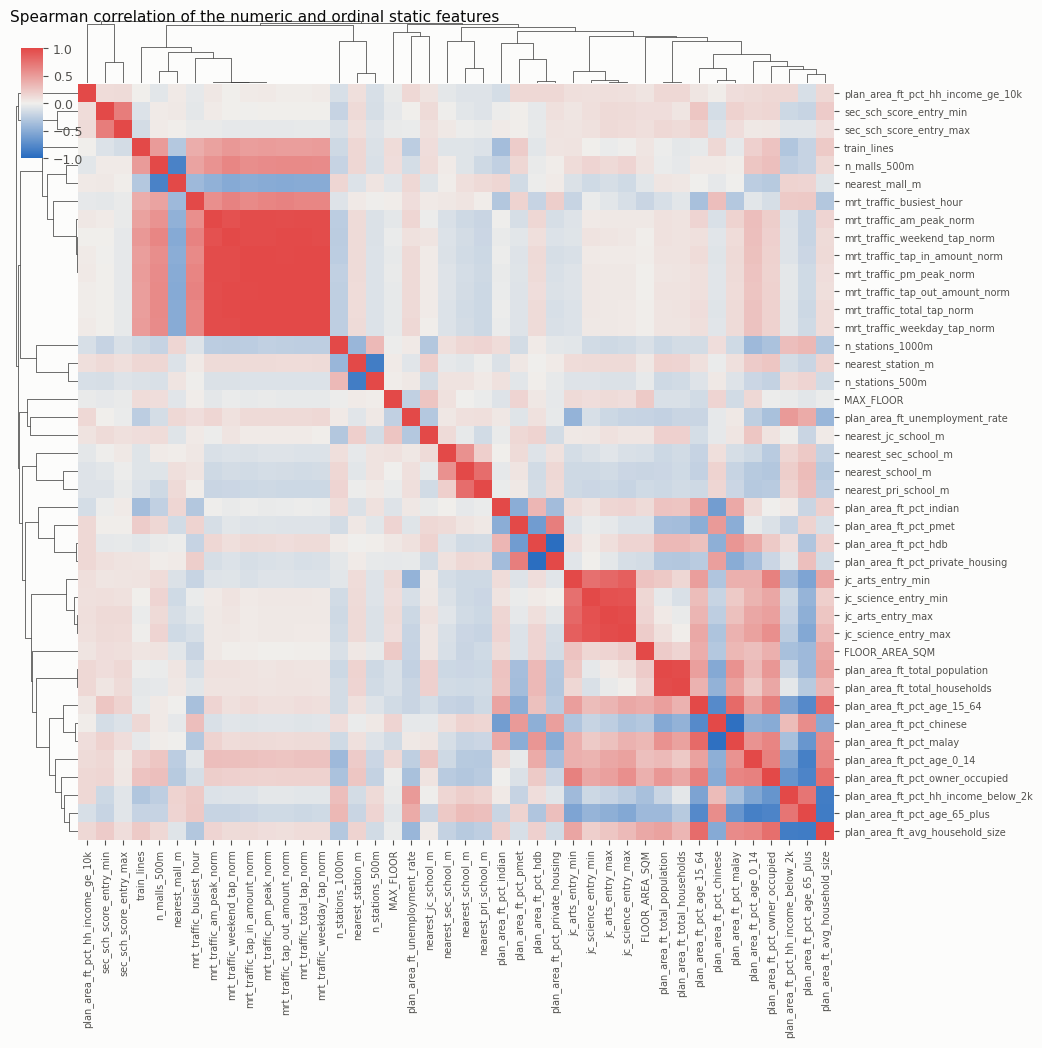

In [20]:
NUMERIC_ORDINAL = [c for c in NUMERICAL_COL + CATEGORICAL_COL if c in STATIC]
corr_n = train[NUMERIC_ORDINAL].corr(method='spearman')
link_n = linkage_of(corr_n)
g = sns.clustermap(corr_n, row_linkage=link_n, col_linkage=link_n, cmap=DIV, vmin=-1, vmax=1, center=0, figsize=(11, 11), dendrogram_ratio=(0.08, 0.08), cbar_pos=(0.02, 0.86, 0.02, 0.1),
                   xticklabels=True, yticklabels=True)
g.ax_heatmap.tick_params(labelsize=7)
g.fig.suptitle('Spearman correlation of the numeric and ordinal static features', x=0.01, y=0.995, ha='left', fontsize=11)
plt.show()

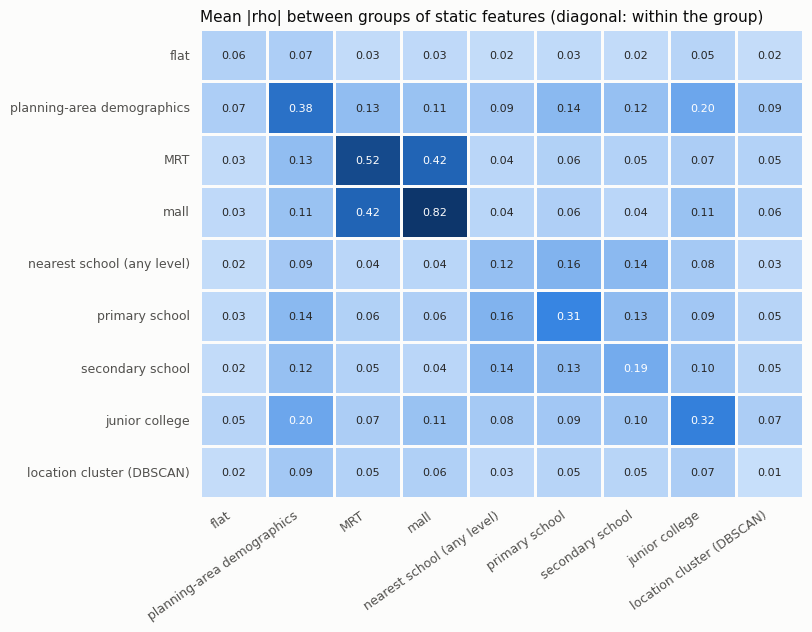

150 static features fall into 137 families at |rho| >= 0.9: 7 families have several members (20 features), 130 features stand alone


,size,representative,min_abs_rho,members
family,,,,
0,7,mrt_traffic_tap_in_amount_norm,0.949518,"mrt_traffic_tap_in_amount_norm, mrt_traffic_tap_out_amount_norm, m..."
1,3,jc_science_entry_max,0.935903,"jc_arts_entry_max, jc_science_entry_min, jc_science_entry_max"
2,2,pri_sch_type_government-aided sch,1.000000,"pri_sch_type_government school, pri_sch_type_government-aided sch"
3,2,nearest_school_type_government school,0.904800,"nearest_school_type_government school, nearest_school_type_governm..."
4,2,plan_area_ft_pct_hdb,0.960984,"plan_area_ft_pct_hdb, plan_area_ft_pct_private_housing"
5,2,plan_area_ft_total_households,0.979313,"plan_area_ft_total_population, plan_area_ft_total_households"
6,2,plan_area_ft_pct_chinese,0.946945,"plan_area_ft_pct_chinese, plan_area_ft_pct_malay"


In [21]:
corr_s = train[STATIC].corr(method='spearman')
group_of = pd.Series([static_group(c) for c in corr_s.columns], index=corr_s.columns)
G = list(GROUPS)
between_s = pd.DataFrame(index=G, columns=G, dtype=float)
for a in G:
    for b in G:
        sub = corr_s.abs().loc[group_of == a, group_of == b].to_numpy()
        between_s.loc[a, b] = (sub[~np.eye(*sub.shape, dtype=bool)].mean() if len(sub) > 1 else np.nan) if a == b else sub.mean()
fig, ax = plt.subplots(figsize=(8.2, 6.4))
sns.heatmap(between_s, annot=True, fmt='.2f', cmap=SEQ, vmin=0, vmax=0.6, cbar=False, ax=ax, linewidths=2, linecolor=SURFACE, annot_kws=dict(fontsize=8))
ax.set_title('Mean |rho| between groups of static features (diagonal: within the group)')
ax.tick_params(left=False, bottom=False)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

fam_s, labels_s = families(corr_s, tab_s)
print(f'{len(corr_s)} static features fall into {len(np.unique(labels_s))} families at |rho| >= {FAMILY_RHO}: {len(fam_s)} families have several members ({fam_s["size"].sum()} features), {(np.bincount(labels_s) == 1).sum()} features stand alone')
display(fam_s.assign(members=fam_s['members'].map(lambda m: ', '.join(m[:6]) + (f' ... (+{len(m) - 6})' if len(m) > 6 else ''))).head(15))
save_table(fam_s.assign(members=fam_s['members'].map('; '.join)), 'static_feature_families')

most correlated pairs of static features (columns of one factor skipped)


,feature_a,feature_b,rho
0,mrt_traffic_total_tap_norm,mrt_traffic_weekday_tap_norm,0.998
1,mrt_traffic_tap_out_amount_norm,mrt_traffic_total_tap_norm,0.998
2,mrt_traffic_weekday_tap_norm,mrt_traffic_pm_peak_norm,0.998
3,mrt_traffic_tap_out_amount_norm,mrt_traffic_weekday_tap_norm,0.997
4,mrt_traffic_tap_in_amount_norm,mrt_traffic_total_tap_norm,0.996
5,mrt_traffic_total_tap_norm,mrt_traffic_pm_peak_norm,0.996
6,mrt_traffic_tap_out_amount_norm,mrt_traffic_pm_peak_norm,0.995
7,mrt_traffic_tap_in_amount_norm,mrt_traffic_weekday_tap_norm,0.995
8,mrt_traffic_tap_in_amount_norm,mrt_traffic_pm_peak_norm,0.992
9,mrt_traffic_tap_in_amount_norm,mrt_traffic_tap_out_amount_norm,0.991


the features most similar to the best static feature, FLOOR_AREA_SQM


,rho
FLAT_TYPE_3 room,-0.764
FLAT_TYPE_5 room,0.625
plan_area_ft_avg_household_size,0.426
plan_area_ft_pct_age_65_plus,-0.402
FLAT_TYPE_executive,0.395
plan_area_ft_pct_age_15_64,0.393
plan_area_ft_pct_owner_occupied,0.377
plan_area_ft_pct_hh_income_below_2k,-0.358


42 numeric and ordinal static features: principal components for 90% / 95% / 99% of the variance: 14 / 18 / 25


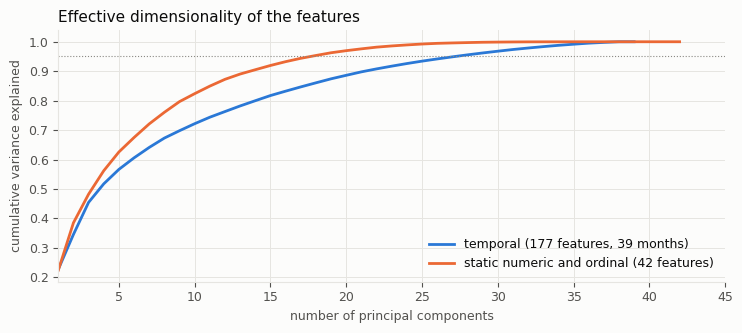

In [22]:
factor_of = {c: p for p in FACTORS for c in HOT_COL if c.startswith(p)}
print('most correlated pairs of static features (columns of one factor skipped)')
display(top_pairs(corr_s, 25, skip=lambda a, b: a in factor_of and factor_of.get(a) == factor_of.get(b)).round(3))
print('the features most similar to the best static feature,', tab_s.index[0])
display(similar_to(corr_s, tab_s.index[0]).round(3))

std_no = train[NUMERIC_ORDINAL]
pca_s = PCA().fit((std_no - std_no.mean()) / std_no.std())
cum_s = np.cumsum(pca_s.explained_variance_ratio_)
print(f'{len(NUMERIC_ORDINAL)} numeric and ordinal static features: principal components for 90% / 95% / 99% of the variance: {np.searchsorted(cum_s, 0.90) + 1} / {np.searchsorted(cum_s, 0.95) + 1} / {np.searchsorted(cum_s, 0.99) + 1}')

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(np.arange(1, len(cum_t) + 1), cum_t, color=BLUE, label=f'temporal ({Z.shape[1]} features, 39 months)')
ax.plot(np.arange(1, len(cum_s) + 1), cum_s, color=ORANGE, label=f'static numeric and ordinal ({len(NUMERIC_ORDINAL)} features)')
ax.axhline(0.95, color=MUTED, lw=0.8, ls=':')
ax.set_xlim(1, 45)
ax.set_xlabel('number of principal components')
ax.set_ylabel('cumulative variance explained')
ax.set_title('Effective dimensionality of the features')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Lookup: which features are similar to a given one?

In [23]:
LOOKUP = 'plan_area_ft_pct_hdb'
print(f'temporal and static features are looked up in their own correlation matrix; {LOOKUP}:')
display(similar_to(corr_s, LOOKUP, 10).round(3))

temporal and static features are looked up in their own correlation matrix; plan_area_ft_pct_hdb:


,rho
plan_area_ft_pct_private_housing,-0.961
plan_area_ft_pct_pmet,-0.618
plan_area_ft_pct_malay,0.534
plan_area_ft_pct_chinese,-0.481
plan_area_ft_pct_age_0_14,0.409
dbscan_cluster_4,-0.384
dbscan_cluster_20,0.373
plan_area_ft_pct_indian,0.343
plan_area_ft_total_households,0.326
pri_sch_type_government-aided sch,-0.321


# Summary of the findings

From the run stored in this notebook (fixed seeds; the tables and charts above are the source if the data change).

**Temporal features (39 train months)**
* Level correlations are large but mostly shared trends: 51 of 177 features correlate with the monthly rent at |rho| > 0.5 (the median of the stock prices, COE and macro features is 0.64-0.68), but the month-to-month changes hardly do (median |rho| 0.04-0.09 for stocks and COE, 0.22 for macro).
  Only one feature, `MACRO_SORA_3M_PCT`, has a significant change correlation after correcting for 177 tests (rho 0.63, q = 0.004). Monthly returns and return volatilities carry almost nothing for the monthly rent (median |rho| of the levels 0.11 and 0.25).
* No single feature forecasts the next six months better than the rent's own time trend or than carrying the last month forward (trend RMSE $195, carry-forward $152): the best are `coe_c_quota_premium` (skill vs trend -0.03) and `stk_sembcorp_log_price_mean` (-0.22). A Lasso on all 177 features, with the penalty tuned by time-series cross-validation (17 features kept), is not better (RMSE $276).
  With 39 months and a trending target this says the features mostly stand in for time inside the train window; it does not prove they are useless for the networks, which combine all of them, but no single temporal feature can be singled out as a driver.
* 160 of 177 features pass none of the three tests (change correlation, forecast skill, Lasso); `MACRO_SORA_3M_PCT` is the only one that passes two.

**Static features (114,841 train rentals, relative rent)**
* The static features explain 39% of the variance of the relative rent on held-out months. The flat itself is almost all of it: the flat features alone reach R² 0.345 and removing them costs 0.115; `FLOOR_AREA_SQM` is the strongest single feature (rho 0.41, permutation importance 0.058), then `MAX_FLOOR`, flat type (adjusted eta² 0.205) and flat model (0.086).
* Every location-type group (MRT 0.21, secondary school 0.17, junior college 0.15, mall 0.09, demographics 0.05, cluster 0.05 alone) is a proxy for where the block is, so they replace one another: removing any single one of them costs at most 0.003 of R². They are redundant with each other, not useless.
* School type, nature and level features are individually weak (eta² at most 0.011); 18 of 150 features show no measurable signal at all, and 14 binary features cover fewer than 0.1% of the rentals.

**DBSCAN clusters**
* The 47 clusters (plus 5 noise blocks, 226 rentals) reproduce the pipeline's cluster file exactly. Rent is highest in the central and southern clusters (cluster 10, central / Bukit Merah: 1.27 times the market of the month, median $3,200) and lowest in Pasir Ris, Geylang and Kallang (clusters 42, 8 and 40: 0.81-0.89) and in Yishun (cluster 5: 0.93).
* As a division of the island the clusters explain as much of the relative rent as planning areas and towns (adjusted eta² 0.056 against 0.057 and 0.055) and less than subzones (0.135); the ceiling set by the block itself is 0.367. Planning area and cluster together explain 0.073, so the clusters add a little beyond the planning areas.

**Similarity**
* Temporal: only 0.2% of the 15,576 pairs have |rho| > 0.9, but the matrix has rank 38 (39 months), and 22 / 28 / 35 principal components hold 90 / 95 / 99% of the variance. The most redundant features are the COE series (mean |rho| 0.70 inside the group; the four quota premiums form one family with `MACRO_PRIVATE_RENT_RPI_YOY`) and the trending stock prices, which are as correlated with the macro series (e.g. `stk_sembcorp_log_price_mean` and `MACRO_UNEMPLOYMENT_SA_PCT`, rho -0.96) as with each other.
* Static: seven MRT traffic columns are the same quantity (|rho| 0.95-1.00), as are the junior-college entry scores (up to 0.98), `plan_area_ft_total_population` and `plan_area_ft_total_households` (0.98), and `plan_area_ft_pct_hdb` and `plan_area_ft_pct_private_housing` (-0.96); the two `pri_sch_type_*` columns are exact complements. Keeping one representative per family (see the families tables) would remove 13 static and 13 temporal features at the 0.9 threshold.